# Ноутбук 3 (Трек C): Полнопротеомная сеть `BINN` / `P-NET` на Когорте Б г. Чунцина ($N=35 \times 2699$), вентиль пропусков, приборные приоры $E_g$ и топологический `DeepSHAP`

**Архитектура экспериментов Трека C (строго на замороженных 50 фолдах `CQ_10x5_CV.json`):**
1. **Exp C1 (`BINN` против `P-NET` и выбор учителя дистилляции):**
   - Канонический **BINN** (`L4`-выход на 6 макро-путей, `LayerNorm`, `tanh`, `full-batch n=28`) против **P-NET** (вспомогательные выходы `L1..L4`).
   - Проверка дистилляции от учителя Этапа 1 (`sPTB_Logit_Soft`) и TFM-учителя Ноутбука 2 (`bridge_cq_TFM.parquet`).
2. **Exp C2 (Четырёхфакторная абляция авторских механизмов и анти-тавтологический контроль):**
   - Реконструкция пропусков: `discovery_wide` (MAR-kNN + MNAR-QRILC) против `discovery_imputed_lod` (Gaussian LOD).
   - Входной **вентильный слой пропусков $(X_{\text{imp}}, M)$** против слепого входа.
   - Приборный штраф первого слоя **$\lambda_g \propto 1/(\max(E_g, 0.05)\cdot \max(\bar{M}_g, 0.05))$** (подавление 48 белков с $E_g = 0$) и **лапласиан мультиплексного графа** коэкспрессии + STRING.
   - **Анти-тавтологический тест (`Masked_Bridge_2695` + `Pure_JSD_Cluster`):** полное удаление 4 маркеров учителя (`AMBP, FN1, LUM, B2M`) и независимая JSD-кластеризация.
3. **Exp C3 (Топологически скорректированный `DeepSHAP` Хартмана $f(S_n) = S_n / \log(N_{\text{SG}_n})$):**
   - Послойная и полнопротеомная атрибуция на OOF-моделях с проверкой общности ядра `ECM` + `Zn/Cu` (`SOD1, ALB, GC, TF`) в обоих подтипах и специфического скачка `Complement_Cascade` / `Immune_Inflammation` (`C3, C4A, CFH, PRG2`) при переходе `sPTB1 -> sPTB2`, а также верификация U-профиля сетевой связности LIONESS $\langle k \rangle$.

In [ ]:
import os
import sys
import json
import zipfile
import shutil
import warnings
from pathlib import Path
from typing import Dict, List, Tuple, Optional, Any

import numpy as np
import pandas as pd
import scipy.stats as stats
from scipy.special import softmax
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

import torch
import torch.nn as nn
import torch.nn.functional as F

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    balanced_accuracy_score,
    log_loss,
    adjusted_rand_score,
    normalized_mutual_info_score,
    confusion_matrix,
)

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
})

print(f"Python: {sys.version.split()[0]} | PyTorch: {torch.__version__} | Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Python: 3.13.16 | PyTorch: 2.14.1+cu130 | Device: cuda
GPU: NVIDIA L4


In [ ]:
def unpack_archive_if_needed(zip_names: List[str], check_file: Path, target_dir: Path) -> Path:
    if check_file.exists():
        return target_dir
    for zname in zip_names:
        for base in [Path("."), Path("/content"), Path("/content/drive/MyDrive")]:
            zp = base / zname
            if zp.exists():
                target_dir.mkdir(parents=True, exist_ok=True)
                print(f"[UNZIP] {zp} -> {target_dir.resolve()}")
                with zipfile.ZipFile(zp, "r") as zf:
                    zf.extractall(target_dir)
                if check_file.exists():
                    return target_dir
                for found in target_dir.rglob(check_file.name):
                    return found.parents[len(check_file.relative_to(target_dir).parts) - 1]
    raise FileNotFoundError(f"Не найден {check_file} или архив из {zip_names}.")

DATA_DIR = unpack_archive_if_needed(["data.zip", "sptb_data.zip"], Path("./data/discovery_wide.parquet"), Path("./data"))
ARTIFACTS_DIR = unpack_archive_if_needed(["artifacts.zip"], Path("./artifacts/splits/CQ_10x5_CV.json"), Path("./artifacts"))

SPLITS_DIR = ARTIFACTS_DIR / "splits"
TRACK_B_DIR = ARTIFACTS_DIR / "track_b"
TRACK_C_DIR = ARTIFACTS_DIR / "track_c"
FIGURES_DIR = ARTIFACTS_DIR / "figures"
for d in [TRACK_C_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

discovery_wide = pd.read_parquet(DATA_DIR / "discovery_wide.parquet")
discovery_lod = pd.read_parquet(DATA_DIR / "discovery_imputed_lod.parquet")
discovery_mask = pd.read_parquet(DATA_DIR / "discovery_missing_mask.parquet")
cohort_b = pd.read_parquet(DATA_DIR / "cohort_b_35_proteome_distilled.parquet")
proteome_priors = pd.read_parquet(DATA_DIR / "proteome_priors_2699.parquet")

binn_npz = np.load(DATA_DIR / "binn_hierarchy_masks.npz", allow_pickle=False)
multiplex_npz = np.load(DATA_DIR / "protein_multiplex_graph.npz", allow_pickle=False)

with open(SPLITS_DIR / "CQ_10x5_CV.json", "r", encoding="utf-8") as f:
    cq_10x5_splits = json.load(f)

bridge_tfm_path = TRACK_B_DIR / "bridge_cq_TFM.parquet"
bridge_tfm_df = pd.read_parquet(bridge_tfm_path) if bridge_tfm_path.exists() else None

assert discovery_wide.shape == (35, 2699)
assert discovery_lod.shape == (35, 2699)
assert discovery_mask.shape == (35, 2699)
assert (discovery_wide.index == cohort_b.index).all()
assert (discovery_wide.index == discovery_mask.index).all()
assert (discovery_wide.columns == binn_npz["node_names_layer_0"]).all()
assert (discovery_wide.columns == proteome_priors.index).all()
assert (discovery_wide.columns == multiplex_npz["node_names"][:2699]).all()

PROTEIN_NAMES = discovery_wide.columns.to_numpy()
SAMPLE_IDS_CQ = discovery_wide.index.to_numpy()
BRIDGE_4 = ["AMBP", "FN1", "LUM", "B2M"]
BRIDGE_4_IDX = [int(np.where(PROTEIN_NAMES == g)[0][0]) for g in BRIDGE_4]

M_LIST = [
    binn_npz["M1"].astype(np.float32),
    binn_npz["M2"].astype(np.float32),
    binn_npz["M3"].astype(np.float32),
    binn_npz["M4"].astype(np.float32),
]
LAYER_NAMES = [
    binn_npz["node_names_layer_0"],
    binn_npz["node_names_layer_1"],
    binn_npz["node_names_layer_2"],
    binn_npz["node_names_layer_3"],
    binn_npz["node_names_layer_4"],
]

def compute_hartman_subgraph_sizes(masks: List[np.ndarray]) -> List[np.ndarray]:
    n_layers = len(masks) + 1
    sizes = [m.shape[0] for m in masks] + [masks[-1].shape[1]]
    reach = {}
    for i in range(n_layers):
        reach[(i, i)] = np.eye(sizes[i], dtype=bool)
        cur = np.eye(sizes[i], dtype=bool)
        for j in range(i, n_layers - 1):
            cur = (cur.astype(np.float32) @ masks[j]) > 0
            reach[(i, j + 1)] = cur
    sg_counts = []
    for l in range(n_layers):
        ancestors = np.zeros(sizes[l], dtype=np.int32)
        for prev_l in range(l):
            ancestors += np.sum(reach[(prev_l, l)], axis=0)
        descendants = np.zeros(sizes[l], dtype=np.int32)
        for next_l in range(l + 1, n_layers):
            descendants += np.sum(reach[(l, next_l)], axis=1)
        sg_counts.append(1 + ancestors + descendants)
    return sg_counts

SUBGRAPH_SIZES = compute_hartman_subgraph_sizes(M_LIST)
L0_TO_L4_REACH = (M_LIST[0] @ M_LIST[1] @ M_LIST[2] @ M_LIST[3]) > 0

E_RAW = proteome_priors["ms_evidence_weight_E"].values.astype(np.float32)
OBS_RATE = discovery_mask.values.mean(axis=0).astype(np.float32)
PRIOR_INV_WEIGHT = 1.0 / (np.maximum(E_RAW, 0.02) * np.maximum(OBS_RATE, 0.05))
PRIOR_INV_WEIGHT = (PRIOR_INV_WEIGHT / np.median(PRIOR_INV_WEIGHT)).astype(np.float32)

edge_idx_all = multiplex_npz["edge_index"]
edge_attr_all = multiplex_npz["edge_attr"]
keep_edges = (edge_idx_all[0] < 2699) & (edge_idx_all[1] < 2699)
MP_SRC = torch.tensor(edge_idx_all[0, keep_edges], dtype=torch.long, device=DEVICE)
MP_DST = torch.tensor(edge_idx_all[1, keep_edges], dtype=torch.long, device=DEVICE)
MP_SIGN = torch.tensor(np.where(edge_attr_all[keep_edges, 1] >= 0, 1.0, -1.0), dtype=torch.float32, device=DEVICE)
MP_WEIGHT = torch.tensor(edge_attr_all[keep_edges, 3], dtype=torch.float32, device=DEVICE)
DEG_2699 = np.zeros(2699, dtype=np.float32)
np.add.at(DEG_2699, edge_idx_all[0, keep_edges], 1.0)
MP_INV_SQRT_DEG = torch.tensor(1.0 / np.sqrt(DEG_2699 + 1.0), dtype=torch.float32, device=DEVICE)

X_wide_raw = discovery_wide.values.astype(np.float32)
X_lod_raw = discovery_lod.values.astype(np.float32)
M_raw = discovery_mask.values.astype(np.float32)

Y_SUBTYPE = cohort_b["Subtype_Cluster"].values.astype(int)
Y_SOFT_PROB = cohort_b["sPTB_Prob_Soft"].values.astype(np.float32)
Y_SOFT_LOGIT = cohort_b["sPTB_Logit_Soft"].values.astype(np.float32)
UNC_STD = cohort_b["Uncertainty_Std"].values.astype(np.float32)
DISTILL_WEIGHT = 1.0 / (UNC_STD ** 2 + 0.01)
DISTILL_WEIGHT = (DISTILL_WEIGHT / np.mean(DISTILL_WEIGHT)).astype(np.float32)

P_cq = np.clip(X_wide_raw, 1e-6, None)
P_cq = P_cq / np.sum(P_cq, axis=1, keepdims=True)
n_cq = P_cq.shape[0]
jsd_mat = np.zeros((n_cq, n_cq), dtype=np.float64)
for i in range(n_cq):
    for j in range(i + 1, n_cq):
        m_ij = 0.5 * (P_cq[i] + P_cq[j])
        d_ij = 0.5 * (np.sum(P_cq[i] * np.log2(P_cq[i] / m_ij)) + np.sum(P_cq[j] * np.log2(P_cq[j] / m_ij)))
        jsd_mat[i, j] = jsd_mat[j, i] = np.sqrt(max(d_ij, 0.0))

Z_link = linkage(squareform(jsd_mat), method="average")
raw_cl = fcluster(Z_link, t=3, criterion="maxclust") - 1
cl_sizes = np.bincount(raw_cl)
ftb_cl_id = int(np.argmax(cl_sizes))
ftb_centroid = np.mean(P_cq[raw_cl == ftb_cl_id], axis=0)
cl_dists = []
for c in range(3):
    pc = np.mean(P_cq[raw_cl == c], axis=0)
    mc = 0.5 * (pc + ftb_centroid)
    dc = 0.5 * (np.sum(pc * np.log2(pc / mc)) + np.sum(ftb_centroid * np.log2(ftb_centroid / mc)))
    cl_dists.append((c, dc))
cl_order = [x[0] for x in sorted(cl_dists, key=lambda t: t[1])]
remap_cl = {old_c: new_c for new_c, old_c in enumerate(cl_order)}
Y_PURE_JSD = np.array([remap_cl[c] for c in raw_cl], dtype=int)

ari_jsd = adjusted_rand_score(Y_SUBTYPE, Y_PURE_JSD)
nmi_jsd = normalized_mutual_info_score(Y_SUBTYPE, Y_PURE_JSD)
print(f"[OK] Pure_JSD_Cluster (n={np.bincount(Y_PURE_JSD).tolist()}) vs Subtype_Cluster: ARI={ari_jsd:.4f}, NMI={nmi_jsd:.4f}")
print(f"[OK] PRIOR_INV_WEIGHT: median(E>0)={np.median(PRIOR_INV_WEIGHT[E_RAW>0]):.2f}, median(E=0)={np.median(PRIOR_INV_WEIGHT[E_RAW==0]):.2f}")

[OK] Pure_JSD_Cluster (n=[25, 9, 1]) vs Subtype_Cluster: ARI=0.4910, NMI=0.5259
[OK] PRIOR_INV_WEIGHT: median(E>0)=0.99, median(E=0)=20.35


In [ ]:
class MissingnessGateLayer(nn.Module):
    def __init__(self, n_features: int):
        super().__init__()
        self.alpha_logits = nn.Parameter(torch.zeros(n_features))
        self.miss_bias = nn.Parameter(torch.zeros(n_features))

    def forward(self, x: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        gate = torch.sigmoid(self.alpha_logits).unsqueeze(0)
        x_miss = gate * x + (1.0 - gate) * self.miss_bias.unsqueeze(0)
        return mask * x + (1.0 - mask) * x_miss


class MaskedOntologicalLinear(nn.Module):
    def __init__(self, mask_matrix: np.ndarray):
        super().__init__()
        in_f, out_f = mask_matrix.shape
        mask_t = torch.tensor(mask_matrix.T, dtype=torch.float32)
        self.register_buffer("mask", mask_t)
        self.weight = nn.Parameter(torch.empty(out_f, in_f))
        self.bias = nn.Parameter(torch.zeros(out_f))
        self.reset_parameters()

    def reset_parameters(self):
        with torch.no_grad():
            fan_in = self.mask.sum(dim=1, keepdim=True).clamp(min=1.0)
            bound = torch.sqrt(3.0 / fan_in)
            rand_w = (torch.rand_like(self.weight) * 2.0 - 1.0) * bound
            self.weight.copy_(rand_w * self.mask)
            nn.init.zeros_(self.bias)

    def effective_weight(self) -> torch.Tensor:
        return self.weight * self.mask

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return F.linear(x, self.effective_weight(), self.bias)


class ProteomeBINN(nn.Module):
    def __init__(
        self,
        masks: List[np.ndarray],
        use_missing_gate: bool = True,
        pnet_skip_heads: bool = False,
        dropout_rate: float = 0.30,
        n_classes: int = 3,
    ):
        super().__init__()
        self.use_missing_gate = use_missing_gate
        self.pnet_skip_heads = pnet_skip_heads
        n_in = masks[0].shape[0]
        self.gate = MissingnessGateLayer(n_in) if use_missing_gate else None

        self.masked_layers = nn.ModuleList([MaskedOntologicalLinear(m) for m in masks])
        self.norms = nn.ModuleList([nn.LayerNorm(m.shape[1]) for m in masks])
        self.drop = nn.Dropout(dropout_rate)

        if pnet_skip_heads:
            self.cls_heads = nn.ModuleList([nn.Linear(m.shape[1], n_classes) for m in masks])
            self.risk_heads = nn.ModuleList([nn.Linear(m.shape[1], 1) for m in masks])
            self.layer_weights = [0.10, 0.20, 0.30, 0.40]
        else:
            d_last = masks[-1].shape[1]
            self.cls_head = nn.Linear(d_last, n_classes)
            self.risk_head = nn.Linear(d_last, 1)

    def apply_input_gate(self, x: torch.Tensor, m: torch.Tensor) -> torch.Tensor:
        if self.gate is not None:
            return self.gate(x, m)
        return x

    def forward_from_effective_input(self, x_eff: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        h = x_eff
        hidden_states = []
        for idx, (ml, ln) in enumerate(zip(self.masked_layers, self.norms)):
            h = ml(h)
            h = ln(h)
            h = torch.tanh(h)
            if idx < len(self.masked_layers) - 1:
                h = self.drop(h)
            hidden_states.append(h)

        l4_act = hidden_states[-1]
        if self.pnet_skip_heads:
            cls_list = [hd(act) for hd, act in zip(self.cls_heads, hidden_states)]
            risk_list = [hd(act).squeeze(-1) for hd, act in zip(self.risk_heads, hidden_states)]
            cls_logits = sum(w * c for w, c in zip(self.layer_weights, cls_list))
            risk_logits = sum(w * r for w, r in zip(self.layer_weights, risk_list))
            return cls_logits, risk_logits, l4_act

        cls_logits = self.cls_head(l4_act)
        risk_logits = self.risk_head(l4_act).squeeze(-1)
        return cls_logits, risk_logits, l4_act

    def forward_from_l4(self, l4_act: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        if self.pnet_skip_heads:
            return self.cls_heads[-1](l4_act), self.risk_heads[-1](l4_act).squeeze(-1)
        return self.cls_head(l4_act), self.risk_head(l4_act).squeeze(-1)

    def forward(self, x: torch.Tensor, m: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        x_eff = self.apply_input_gate(x, m)
        return self.forward_from_effective_input(x_eff)


def compute_structural_losses(
    model: ProteomeBINN,
    prior_inv_w: torch.Tensor,
    use_prior_penalty: bool = True,
    lambda_prior: float = 1.5e-3,
    use_laplacian: bool = True,
    lambda_lap: float = 1.5e-2,
) -> Tuple[torch.Tensor, float, float]:
    w1 = model.masked_layers[0].effective_weight()
    reg_loss = torch.tensor(0.0, device=w1.device)
    p_val, l_val = 0.0, 0.0

    if use_prior_penalty:
        col_sq = torch.sum(w1 ** 2, dim=0)
        lp = lambda_prior * torch.sum(col_sq * prior_inv_w)
        reg_loss = reg_loss + lp
        p_val = float(lp.detach().item())

    if use_laplacian:
        w1_norm = w1 * MP_INV_SQRT_DEG.unsqueeze(0)
        diff_edges = w1_norm[:, MP_SRC] - MP_SIGN.unsqueeze(0) * w1_norm[:, MP_DST]
        edge_sq = torch.sum(diff_edges ** 2, dim=0)
        ll = lambda_lap * (torch.sum(MP_WEIGHT * edge_sq) / 303.0)
        reg_loss = reg_loss + ll
        l_val = float(ll.detach().item())

    return reg_loss, p_val, l_val

print("[OK] Исправленные штрафы (sum вместо mean) готовы.")

[OK] Исправленные штрафы (sum вместо mean) готовы.


In [ ]:
def run_chongqing_50fold_cv(
    exp_name: str,
    X_source: np.ndarray,
    M_source: np.ndarray,
    y_cls_target: np.ndarray,
    y_risk_target: np.ndarray,
    distill_w: np.ndarray,
    masks_in: List[np.ndarray],
    use_missing_gate: bool = True,
    pnet_skip_heads: bool = False,
    use_prior_penalty: bool = True,
    use_laplacian: bool = True,
    lambda_prior: float = 1.5e-3,
    lambda_lap: float = 1.5e-2,
    lambda_distill: float = 0.50,
    mask_bridge_markers: bool = False,
    epochs: int = 120,
    lr: float = 3e-3,
    weight_decay: float = 1e-3,
    dropout_rate: float = 0.30,
    collect_models: bool = False,
    log_diag: bool = False,
) -> Dict[str, Any]:
    n_samples = X_source.shape[0]
    n_repeats = 10

    X_work = X_source.copy()
    M_work = M_source.copy()
    masks_work = [m.copy() for m in masks_in]
    if mask_bridge_markers:
        X_work[:, BRIDGE_4_IDX] = 0.0
        M_work[:, BRIDGE_4_IDX] = 0.0
        masks_work[0][BRIDGE_4_IDX, :] = 0.0

    oof_cls_logits = np.zeros((n_repeats, n_samples, 3), dtype=np.float32)
    oof_risk_logits = np.zeros((n_repeats, n_samples), dtype=np.float32)
    oof_l4_acts = np.zeros((n_repeats, n_samples, 6), dtype=np.float32)

    prior_t = torch.tensor(PRIOR_INV_WEIGHT, dtype=torch.float32, device=DEVICE)
    saved_folds = []

    for sp in cq_10x5_splits:
        s_id = sp["split_id"]
        rep = sp["repeat"]
        tr_pos = np.array(sp["train_pos"], dtype=int)
        val_pos = np.array(sp["val_pos"], dtype=int)

        torch.manual_seed(SEED + s_id)

        sc = RobustScaler()
        X_tr_s = np.clip(sc.fit_transform(X_work[tr_pos]), -5.0, 5.0).astype(np.float32)
        X_val_s = np.clip(sc.transform(X_work[val_pos]), -5.0, 5.0).astype(np.float32)
        if mask_bridge_markers:
            X_tr_s[:, BRIDGE_4_IDX] = 0.0
            X_val_s[:, BRIDGE_4_IDX] = 0.0

        x_tr_t = torch.tensor(X_tr_s, dtype=torch.float32, device=DEVICE)
        m_tr_t = torch.tensor(M_work[tr_pos], dtype=torch.float32, device=DEVICE)
        x_val_t = torch.tensor(X_val_s, dtype=torch.float32, device=DEVICE)
        m_val_t = torch.tensor(M_work[val_pos], dtype=torch.float32, device=DEVICE)

        y_cls_tr = torch.tensor(y_cls_target[tr_pos], dtype=torch.long, device=DEVICE)
        y_risk_tr = torch.tensor(y_risk_target[tr_pos], dtype=torch.float32, device=DEVICE)
        dw_tr = torch.tensor(distill_w[tr_pos], dtype=torch.float32, device=DEVICE)

        counts = np.bincount(y_cls_target[tr_pos], minlength=3).astype(np.float32)
        cls_w = len(tr_pos) / (3.0 * np.maximum(counts, 1.0))
        cls_w_t = torch.tensor(cls_w, dtype=torch.float32, device=DEVICE)

        model = ProteomeBINN(
            masks=masks_work,
            use_missing_gate=use_missing_gate,
            pnet_skip_heads=pnet_skip_heads,
            dropout_rate=dropout_rate,
            n_classes=3,
        ).to(DEVICE)

        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=lr * 0.1)

        for ep in range(epochs):
            model.train()
            opt.zero_grad()
            c_log, r_log, _ = model(x_tr_t, m_tr_t)
            loss_ce = F.cross_entropy(c_log, y_cls_tr, weight=cls_w_t)
            loss_dist = torch.mean(dw_tr * F.smooth_l1_loss(r_log, y_risk_tr, reduction="none", beta=0.5))
            loss_reg, pv, lv = compute_structural_losses(
                model, prior_t, use_prior_penalty=use_prior_penalty, lambda_prior=lambda_prior,
                use_laplacian=use_laplacian, lambda_lap=lambda_lap,
            )
            loss = loss_ce + lambda_distill * loss_dist + loss_reg
            if log_diag and s_id == 0 and ep in (0, epochs - 1):
                print(f"  [{exp_name} | split0 ep{ep}] CE={loss_ce.item():.3f} Dist={loss_dist.item():.3f} Prior={pv:.3f} Lap={lv:.3f}")
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            opt.step()
            sched.step()

        model.eval()
        with torch.no_grad():
            c_val, r_val, l4_val = model(x_val_t, m_val_t)
            oof_cls_logits[rep, val_pos] = c_val.detach().cpu().numpy()
            oof_risk_logits[rep, val_pos] = r_val.detach().cpu().numpy()
            oof_l4_acts[rep, val_pos] = l4_val.detach().cpu().numpy()

        if collect_models:
            saved_folds.append({
                "split_id": s_id,
                "rep": rep,
                "tr_pos": tr_pos,
                "val_pos": val_pos,
                "model_state": {k: v.detach().cpu() for k, v in model.state_dict().items()},
                "scaler": sc,
                "masks": masks_work,
            })

    rep_macro_auc, rep_macro_f1, rep_bal_acc, rep_ce = [], [], [], []
    rep_r_pearson, rep_r_spearman, rep_rmse = [], [], []

    for r in range(n_repeats):
        probs_r = softmax(oof_cls_logits[r], axis=1)
        preds_r = np.argmax(probs_r, axis=1)
        rep_macro_auc.append(roc_auc_score(y_cls_target, probs_r, multi_class="ovr", average="macro"))
        rep_macro_f1.append(f1_score(y_cls_target, preds_r, average="macro"))
        rep_bal_acc.append(balanced_accuracy_score(y_cls_target, preds_r))
        rep_ce.append(log_loss(y_cls_target, probs_r, labels=[0, 1, 2]))

        r_pred = oof_risk_logits[r]
        rep_r_pearson.append(stats.pearsonr(r_pred, y_risk_target)[0])
        rep_r_spearman.append(stats.spearmanr(r_pred, y_risk_target)[0])
        rep_rmse.append(float(np.sqrt(np.mean((r_pred - y_risk_target) ** 2))))

    mean_cls_probs = softmax(np.mean(oof_cls_logits, axis=0), axis=1)
    mean_risk_logits = np.mean(oof_risk_logits, axis=0)
    mean_l4_acts = np.mean(oof_l4_acts, axis=0)

    return {
        "Exp": exp_name,
        "use_missing_gate": use_missing_gate,
        "pnet_skip_heads": pnet_skip_heads,
        "Macro_AUROC": f"{np.mean(rep_macro_auc):.4f} ± {np.std(rep_macro_auc):.4f}",
        "Macro_F1": f"{np.mean(rep_macro_f1):.4f} ± {np.std(rep_macro_f1):.4f}",
        "Bal_Acc": f"{np.mean(rep_bal_acc):.4f} ± {np.std(rep_bal_acc):.4f}",
        "LogLoss": f"{np.mean(rep_ce):.4f}",
        "Risk_Pearson_r": f"{np.mean(rep_r_pearson):.4f} ± {np.std(rep_r_pearson):.4f}",
        "Risk_Spearman_rho": f"{np.mean(rep_r_spearman):.4f}",
        "Risk_RMSE": f"{np.mean(rep_rmse):.4f}",
        "raw_macro_auc": float(np.mean(rep_macro_auc)),
        "raw_macro_f1": float(np.mean(rep_macro_f1)),
        "raw_risk_r": float(np.mean(rep_r_pearson)),
        "oof_cls_probs": mean_cls_probs,
        "oof_risk_logits": mean_risk_logits,
        "oof_l4_acts": mean_l4_acts,
        "saved_folds": saved_folds,
    }


exp_c1_c2_configs = [
    ("C1a_BINN_Full_BaseTeacher", X_wide_raw, M_raw, Y_SUBTYPE, Y_SOFT_LOGIT, DISTILL_WEIGHT, True, False, True, True, False),
    ("C1b_PNET_SkipHeads_BaseTeacher", X_wide_raw, M_raw, Y_SUBTYPE, Y_SOFT_LOGIT, DISTILL_WEIGHT, True, True, True, True, False),
]

if bridge_tfm_df is not None:
    tfm_logit = bridge_tfm_df["sPTB_Logit_TFM"].values.astype(np.float32)
    tfm_w = 1.0 / (bridge_tfm_df["Uncertainty_Std_TFM"].values.astype(np.float32) ** 2 + 0.01)
    tfm_w = (tfm_w / np.mean(tfm_w)).astype(np.float32)
    exp_c1_c2_configs.append(
        ("C1c_PNET_SkipHeads_TFMTeacher", X_wide_raw, M_raw, Y_SUBTYPE, tfm_logit, tfm_w, True, True, True, True, False)
    )

exp_c1_c2_configs.extend([
    ("C2_PNET_Abl_GaussianLOD", X_lod_raw, M_raw, Y_SUBTYPE, Y_SOFT_LOGIT, DISTILL_WEIGHT, True, True, True, True, False),
    ("C2_PNET_Abl_NoMissingGate", X_wide_raw, M_raw, Y_SUBTYPE, Y_SOFT_LOGIT, DISTILL_WEIGHT, False, True, True, True, False),
    ("C2_PNET_Abl_NoPriorPenalty_Eg", X_wide_raw, M_raw, Y_SUBTYPE, Y_SOFT_LOGIT, DISTILL_WEIGHT, True, True, False, True, False),
    ("C2_PNET_Abl_NoGraphLaplacian", X_wide_raw, M_raw, Y_SUBTYPE, Y_SOFT_LOGIT, DISTILL_WEIGHT, True, True, True, False, False),
    ("C2_PNET_Abl_Vanilla_NoExtras", X_wide_raw, M_raw, Y_SUBTYPE, Y_SOFT_LOGIT, DISTILL_WEIGHT, False, True, False, False, False),
    ("C2b_PNET_AntiTautology_No4Bridge", X_wide_raw, M_raw, Y_SUBTYPE, Y_SOFT_LOGIT, DISTILL_WEIGHT, True, True, True, True, True),
    ("C2c_PNET_AntiTautology_PureJSD", X_wide_raw, M_raw, Y_PURE_JSD, Y_SOFT_LOGIT, DISTILL_WEIGHT, True, True, True, True, True),
])

track_c_results = {}
rows_c = []
for cfg in exp_c1_c2_configs:
    name, x_src, m_src, y_c, y_r, dw, use_mg, pnet_sk, use_pr, use_lap, mask_br = cfg
    need_models = name in (
        "C1a_BINN_Full_BaseTeacher",
        "C1b_PNET_SkipHeads_BaseTeacher",
        "C2b_PNET_AntiTautology_No4Bridge",
        "C2_PNET_Abl_NoPriorPenalty_Eg",
    )
    need_diag = name in ("C1b_PNET_SkipHeads_BaseTeacher", "C2_PNET_Abl_NoPriorPenalty_Eg")
    res = run_chongqing_50fold_cv(
        exp_name=name,
        X_source=x_src,
        M_source=m_src,
        y_cls_target=y_c,
        y_risk_target=y_r,
        distill_w=dw,
        masks_in=M_LIST,
        use_missing_gate=use_mg,
        pnet_skip_heads=pnet_sk,
        use_prior_penalty=use_pr,
        use_laplacian=use_lap,
        mask_bridge_markers=mask_br,
        collect_models=need_models,
        log_diag=need_diag,
    )
    track_c_results[name] = res
    rows_c.append({k: res[k] for k in ["Exp", "Macro_AUROC", "Macro_F1", "Bal_Acc", "LogLoss", "Risk_Pearson_r", "Risk_Spearman_rho", "Risk_RMSE"]})

df_c1_c2 = pd.DataFrame(rows_c)
print("\n=== РЕЗУЛЬТАТЫ EXP C1 & C2 (50 ФОЛДОВ CQ_10x5_CV: ИСПРАВЛЕННЫЕ ШТРАФЫ И АБЛЯЦИИ НА P-NET) ===")
print(df_c1_c2.to_string(index=False))

cm_c1b = confusion_matrix(Y_SUBTYPE, np.argmax(track_c_results["C1b_PNET_SkipHeads_BaseTeacher"]["oof_cls_probs"], axis=1), labels=[0, 1, 2])
print("\n[OOF Матрица ошибок C1b_PNET_SkipHeads по подтипам 0:FTB / 1:sPTB1 / 2:sPTB2]:")
print(cm_c1b)

  [C1b_PNET_SkipHeads_BaseTeacher | split0 ep0] CE=1.070 Dist=1.699 Prior=0.865 Lap=0.003
  [C1b_PNET_SkipHeads_BaseTeacher | split0 ep119] CE=0.062 Dist=0.147 Prior=0.357 Lap=0.001
  [C2_PNET_Abl_NoPriorPenalty_Eg | split0 ep0] CE=1.070 Dist=1.699 Prior=0.000 Lap=0.003
  [C2_PNET_Abl_NoPriorPenalty_Eg | split0 ep119] CE=0.060 Dist=0.161 Prior=0.000 Lap=0.003

=== РЕЗУЛЬТАТЫ EXP C1 & C2 (50 ФОЛДОВ CQ_10x5_CV: ИСПРАВЛЕННЫЕ ШТРАФЫ И АБЛЯЦИИ НА P-NET) ===
                             Exp     Macro_AUROC        Macro_F1         Bal_Acc LogLoss  Risk_Pearson_r Risk_Spearman_rho Risk_RMSE
       C1a_BINN_Full_BaseTeacher 0.8889 ± 0.0563 0.7360 ± 0.0872 0.7492 ± 0.0873  0.6563 0.6566 ± 0.0417            0.6688    1.4404
  C1b_PNET_SkipHeads_BaseTeacher 0.9321 ± 0.0259 0.7763 ± 0.0687 0.7818 ± 0.0636  0.4415 0.7466 ± 0.0429            0.7610    1.2523
   C1c_PNET_SkipHeads_TFMTeacher 0.9332 ± 0.0271 0.7699 ± 0.0558 0.7753 ± 0.0574  0.4458 0.7273 ± 0.0334            0.7370    1.5147
         C2

In [ ]:
def compute_oof_hartman_deepshap(
    run_result: Dict[str, Any],
    X_source: np.ndarray,
    M_source: np.ndarray,
    y_cls_ref: np.ndarray,
    mask_bridge_markers: bool = False,
    n_quad_steps: int = 20,
) -> Dict[str, Any]:
    saved_folds = run_result["saved_folds"]
    use_mg = run_result["use_missing_gate"]
    pnet_sk = run_result["pnet_skip_heads"]
    n_samples, n_prot = X_source.shape
    n_l4 = 6

    X_work = X_source.copy()
    M_work = M_source.copy()
    if mask_bridge_markers:
        X_work[:, BRIDGE_4_IDX] = 0.0
        M_work[:, BRIDGE_4_IDX] = 0.0

    shap_l0_cls = np.zeros((10, n_samples, 3, n_prot), dtype=np.float32)
    shap_l0_risk = np.zeros((10, n_samples, n_prot), dtype=np.float32)
    shap_l4_cls = np.zeros((10, n_samples, 3, n_l4), dtype=np.float32)
    shap_l4_risk = np.zeros((10, n_samples, n_l4), dtype=np.float32)
    completeness_errs = []

    alphas = torch.linspace(0.5 / n_quad_steps, 1.0 - 0.5 / n_quad_steps, n_quad_steps, device=DEVICE).view(-1, 1, 1)

    for fd in saved_folds:
        rep = fd["rep"]
        tr_pos = fd["tr_pos"]
        val_pos = fd["val_pos"]
        sc = fd["scaler"]

        X_tr_s = np.clip(sc.transform(X_work[tr_pos]), -5.0, 5.0).astype(np.float32)
        X_val_s = np.clip(sc.transform(X_work[val_pos]), -5.0, 5.0).astype(np.float32)
        if mask_bridge_markers:
            X_tr_s[:, BRIDGE_4_IDX] = 0.0
            X_val_s[:, BRIDGE_4_IDX] = 0.0

        model = ProteomeBINN(
            masks=fd["masks"],
            use_missing_gate=use_mg,
            pnet_skip_heads=pnet_sk,
            dropout_rate=0.30,
            n_classes=3,
        ).to(DEVICE)
        model.load_state_dict({k: v.to(DEVICE) for k, v in fd["model_state"].items()})
        model.eval()

        ftb_local = np.where(y_cls_ref[tr_pos] == 0)[0]
        x_bg_t = torch.tensor(X_tr_s[ftb_local], dtype=torch.float32, device=DEVICE)
        m_bg_t = torch.tensor(M_work[tr_pos][ftb_local], dtype=torch.float32, device=DEVICE)
        x_val_t = torch.tensor(X_val_s, dtype=torch.float32, device=DEVICE)
        m_val_t = torch.tensor(M_work[val_pos], dtype=torch.float32, device=DEVICE)

        with torch.no_grad():
            eff_bg = model.apply_input_gate(x_bg_t, m_bg_t)
            eff_val = model.apply_input_gate(x_val_t, m_val_t)
            bg_cls, bg_risk, l4_bg = model.forward_from_effective_input(eff_bg)
            val_cls, val_risk, l4_val = model.forward_from_effective_input(eff_val)

        n_bg = eff_bg.shape[0]
        for idx_v, g_i in enumerate(val_pos):
            x_v = eff_val[idx_v : idx_v + 1]
            diff_l0 = x_v.unsqueeze(0) - eff_bg.unsqueeze(1)
            interp_l0 = eff_bg.unsqueeze(0) + alphas * diff_l0.squeeze(1).unsqueeze(0)
            flat_l0 = interp_l0.reshape(-1, n_prot).detach().requires_grad_(True)

            c_out, r_out, _ = model.forward_from_effective_input(flat_l0)

            r_grad = torch.autograd.grad(r_out.sum(), flat_l0, retain_graph=True)[0]
            r_attr = (diff_l0.squeeze(1).unsqueeze(0) * r_grad.view(n_quad_steps, n_bg, n_prot)).mean(dim=(0, 1))
            shap_l0_risk[rep, g_i] = r_attr.detach().cpu().numpy()

            err_r = abs(float(r_attr.sum().item()) - float((val_risk[idx_v] - bg_risk.mean()).item()))
            completeness_errs.append(err_r)

            for cls_k in range(3):
                c_grad = torch.autograd.grad(c_out[:, cls_k].sum(), flat_l0, retain_graph=(cls_k < 2))[0]
                c_attr = (diff_l0.squeeze(1).unsqueeze(0) * c_grad.view(n_quad_steps, n_bg, n_prot)).mean(dim=(0, 1))
                shap_l0_cls[rep, g_i, cls_k] = c_attr.detach().cpu().numpy()

            l4_v = l4_val[idx_v : idx_v + 1]
            diff_l4 = l4_v.unsqueeze(0) - l4_bg.unsqueeze(1)
            interp_l4 = l4_bg.unsqueeze(0) + alphas * diff_l4.squeeze(1).unsqueeze(0)
            flat_l4 = interp_l4.reshape(-1, n_l4).detach().requires_grad_(True)

            c_l4_out, r_l4_out = model.forward_from_l4(flat_l4)
            r_l4_g = torch.autograd.grad(r_l4_out.sum(), flat_l4, retain_graph=True)[0]
            r_l4_attr = (diff_l4.squeeze(1).unsqueeze(0) * r_l4_g.view(n_quad_steps, n_bg, n_l4)).mean(dim=(0, 1))
            shap_l4_risk[rep, g_i] = r_l4_attr.detach().cpu().numpy()

            for cls_k in range(3):
                c_l4_g = torch.autograd.grad(c_l4_out[:, cls_k].sum(), flat_l4, retain_graph=(cls_k < 2))[0]
                c_l4_attr = (diff_l4.squeeze(1).unsqueeze(0) * c_l4_g.view(n_quad_steps, n_bg, n_l4)).mean(dim=(0, 1))
                shap_l4_cls[rep, g_i, cls_k] = c_l4_attr.detach().cpu().numpy()

    mean_l0_cls = np.mean(shap_l0_cls, axis=0)
    mean_l0_risk = np.mean(shap_l0_risk, axis=0)
    mean_l4_cls = np.mean(shap_l4_cls, axis=0)
    mean_l4_risk = np.mean(shap_l4_risk, axis=0)

    log_sg_l0 = np.log(SUBGRAPH_SIZES[0].astype(np.float32))
    log_sg_l4 = np.log(SUBGRAPH_SIZES[4].astype(np.float32))

    reach_f = L0_TO_L4_REACH.astype(np.float32)
    l4_from_l0_cls = np.einsum("nck,kp->ncp", mean_l0_cls, reach_f) / log_sg_l4[None, None, :]
    l4_from_l0_risk = (mean_l0_risk @ reach_f) / log_sg_l4[None, :]

    return {
        "l0_cls": mean_l0_cls,
        "l0_risk": mean_l0_risk,
        "l0_cls_hartman": mean_l0_cls / log_sg_l0[None, None, :],
        "l0_risk_hartman": mean_l0_risk / log_sg_l0[None, :],
        "l4_cls_hartman": l4_from_l0_cls if pnet_sk else (mean_l4_cls / log_sg_l4[None, None, :]),
        "l4_risk_hartman": l4_from_l0_risk if pnet_sk else (mean_l4_risk / log_sg_l4[None, :]),
        "completeness_mae": float(np.mean(completeness_errs)),
    }


shap_pnet_full = compute_oof_hartman_deepshap(
    track_c_results["C1b_PNET_SkipHeads_BaseTeacher"], X_wide_raw, M_raw, Y_SUBTYPE, mask_bridge_markers=False
)
shap_pnet_nobridge = compute_oof_hartman_deepshap(
    track_c_results["C2b_PNET_AntiTautology_No4Bridge"], X_wide_raw, M_raw, Y_SUBTYPE, mask_bridge_markers=True
)
shap_pnet_noprior = compute_oof_hartman_deepshap(
    track_c_results["C2_PNET_Abl_NoPriorPenalty_Eg"], X_wide_raw, M_raw, Y_SUBTYPE, mask_bridge_markers=False
)

print(f"[DEEPSHAP COMPLETENESS CHECK] P-NET Full MAE={shap_pnet_full['completeness_mae']:.2e} | P-NET No4Bridge MAE={shap_pnet_nobridge['completeness_mae']:.2e}")

m_c0 = Y_SUBTYPE == 0
m_c1 = Y_SUBTYPE == 1
m_c2 = Y_SUBTYPE == 2

l4_rows = []
for idx_p, pname in enumerate(LAYER_NAMES[4]):
    sh_c1 = float(np.mean(shap_pnet_full["l4_cls_hartman"][m_c1, 1, idx_p]))
    sh_c2 = float(np.mean(shap_pnet_full["l4_cls_hartman"][m_c2, 2, idx_p]))
    sh_risk_all = float(np.mean(np.abs(shap_pnet_full["l4_risk_hartman"][:, idx_p])))
    sh_nb_c2 = float(np.mean(shap_pnet_nobridge["l4_cls_hartman"][m_c2, 2, idx_p]))
    sh_nb_risk = float(np.mean(np.abs(shap_pnet_nobridge["l4_risk_hartman"][:, idx_p])))
    l4_rows.append({
        "Macro_Pathway_L4": pname,
        "Subgraph_N_SG": int(SUBGRAPH_SIZES[4][idx_p]),
        "PNET_SHAP_sPTB1": round(sh_c1, 4),
        "PNET_SHAP_sPTB2": round(sh_c2, 4),
        "Delta_sPTB2_vs_1": round(sh_c2 - sh_c1, 4),
        "PNET_Risk_Abs": round(sh_risk_all, 4),
        "No4Bridge_SHAP_sPTB2": round(sh_nb_c2, 4),
        "No4Bridge_Risk_Abs": round(sh_nb_risk, 4),
    })

df_l4_biology = pd.DataFrame(l4_rows).sort_values("PNET_Risk_Abs", ascending=False)
print("\n=== EXP C3: АТРИБУЦИЯ 6 МАКРО-ПУТЕЙ L4 НА P-NET (ПОПРАВКА ХАРТМАНА S_n / log(N_SG)) ===")
print(df_l4_biology.to_string(index=False))

full_imp = np.mean(np.abs(shap_pnet_full["l0_risk_hartman"]), axis=0)
noprior_imp = np.mean(np.abs(shap_pnet_noprior["l0_risk_hartman"]), axis=0)
mask_e0 = E_RAW == 0.0

print("\n=== ПРОВЕРКА ПОДАВЛЕНИЯ 48 ШУМОВЫХ ИЗОФОРМ (E_g = 0) ПОСЛЕ ИСПРАВЛЕНИЯ ШТРАФА ===")
print(f"Без штрафа E_g: Mean |SHAP| для 48 изоформ (E_g=0) = {np.mean(noprior_imp[mask_e0]):.5f} vs Аннотированных = {np.mean(noprior_imp[~mask_e0]):.5f} (Отношение = {np.mean(noprior_imp[mask_e0]) / np.mean(noprior_imp[~mask_e0]):.3f}x)")
print(f"Со штрафом E_g: Mean |SHAP| для 48 изоформ (E_g=0) = {np.mean(full_imp[mask_e0]):.5f} vs Аннотированных = {np.mean(full_imp[~mask_e0]):.5f} (Отношение = {np.mean(full_imp[mask_e0]) / np.mean(full_imp[~mask_e0]):.3f}x)")

KEY_BIO_GENES = [
    "LUM", "FN1", "AMBP", "B2M",
    "COL1A2", "THBS1", "PLG", "SERPINA1",
    "C3", "C4A", "CFH", "PRG2",
    "SOD1", "ALB", "GC", "TF",
]

ranks_full = stats.rankdata(-np.mean(np.abs(shap_pnet_full["l0_risk_hartman"]), axis=0))
ranks_nobridge = stats.rankdata(-np.mean(np.abs(shap_pnet_nobridge["l0_risk_hartman"]), axis=0))

bio_rows = []
for g in KEY_BIO_GENES:
    idx_g = int(np.where(PROTEIN_NAMES == g)[0][0])
    p_cols = LAYER_NAMES[4][L0_TO_L4_REACH[idx_g]].tolist()
    p_str = "+".join(p_cols) if p_cols else "Other_Proteome"
    bio_rows.append({
        "Gene": g,
        "Pathway": p_str[:24],
        "E_g": round(float(E_RAW[idx_g]), 3),
        "Rank_Full_2699": int(ranks_full[idx_g]),
        "Rank_NoBridge_2695": int(ranks_nobridge[idx_g]),
        "Risk_SHAP_Full": round(float(np.mean(np.abs(shap_pnet_full["l0_risk_hartman"][:, idx_g]))), 5),
        "sPTB1_SHAP": round(float(np.mean(shap_pnet_full["l0_cls_hartman"][m_c1, 1, idx_g])), 5),
        "sPTB2_SHAP": round(float(np.mean(shap_pnet_full["l0_cls_hartman"][m_c2, 2, idx_g])), 5),
        "NoBridge_Risk_SHAP": round(float(np.mean(np.abs(shap_pnet_nobridge["l0_risk_hartman"][:, idx_g]))), 5),
    })

df_bio_markers = pd.DataFrame(bio_rows).sort_values("Rank_Full_2699")
print("\n=== ПРОВЕРКА КЛЮЧЕВЫХ БИОМАРКЕРОВ СТАТЬИ ZHAO ET AL. НА P-NET ===")
print(df_bio_markers.to_string(index=False))

top20_nobridge_idx = np.argsort(-np.mean(np.abs(shap_pnet_nobridge["l0_risk_hartman"]), axis=0))[:20]
top20_df = pd.DataFrame({
    "Rank": np.arange(1, 21),
    "Gene": PROTEIN_NAMES[top20_nobridge_idx],
    "E_g": np.round(E_RAW[top20_nobridge_idx], 3),
    "NoBridge_Risk_SHAP": np.round(np.mean(np.abs(shap_pnet_nobridge["l0_risk_hartman"][:, top20_nobridge_idx]), axis=0), 5),
    "sPTB1_Cls_SHAP": np.round(np.mean(shap_pnet_nobridge["l0_cls_hartman"][m_c1, 1][:, top20_nobridge_idx], axis=0), 5),
    "sPTB2_Cls_SHAP": np.round(np.mean(shap_pnet_nobridge["l0_cls_hartman"][m_c2, 2][:, top20_nobridge_idx], axis=0), 5),
})
print("\n=== ТОП-20 БЕЛКОВ ПО DEEPSHAP БЕЗ 4 МОСТОВЫХ МАРКЕРОВ (P-NET, БЕЗ E_g=0 ШУМА) ===")
print(top20_df.to_string(index=False))

pred_subtype_oof = np.argmax(track_c_results["C1b_PNET_SkipHeads_BaseTeacher"]["oof_cls_probs"], axis=1)
lioness_k = cohort_b["Sample_Mean_Degree"].values
jsd_ftb = cohort_b["JSD_to_FTB_Centroid"].values
zncu_sc = cohort_b["Zn_Cu_Target_Score"].values
comp_sc = cohort_b["Complement_Activity_Score"].values

lioness_rows = []
for cl_id, cl_name in [(0, "Pred_0_FTB_like"), (1, "Pred_1_sPTB1_Matrix"), (2, "Pred_2_sPTB2_Immune")]:
    m_p = pred_subtype_oof == cl_id
    lioness_rows.append({
        "OOF_Predicted_Subtype": cl_name,
        "N": int(np.sum(m_p)),
        "Mean_LIONESS_k": round(float(np.mean(lioness_k[m_p])), 2) if np.sum(m_p) > 0 else np.nan,
        "Mean_JSD_FTB": round(float(np.mean(jsd_ftb[m_p])), 4) if np.sum(m_p) > 0 else np.nan,
        "Mean_ZnCu_Score": round(float(np.mean(zncu_sc[m_p])), 4) if np.sum(m_p) > 0 else np.nan,
        "Mean_Complement_Score": round(float(np.mean(comp_sc[m_p])), 4) if np.sum(m_p) > 0 else np.nan,
    })

print("\n=== ВОСПРОИЗВЕДЕНИЕ U-ОБРАЗНОГО ПРОФИЛЯ СЕТИ LIONESS НА OOF-ПРОГНОЗАХ P-NET ===")
print(pd.DataFrame(lioness_rows).to_string(index=False))

[DEEPSHAP COMPLETENESS CHECK] P-NET Full MAE=7.76e-04 | P-NET No4Bridge MAE=8.35e-04

=== EXP C3: АТРИБУЦИЯ 6 МАКРО-ПУТЕЙ L4 НА P-NET (ПОПРАВКА ХАРТМАНА S_n / log(N_SG)) ===
        Macro_Pathway_L4  Subgraph_N_SG  PNET_SHAP_sPTB1  PNET_SHAP_sPTB2  Delta_sPTB2_vs_1  PNET_Risk_Abs  No4Bridge_SHAP_sPTB2  No4Bridge_Risk_Abs
   Energy_Metabolism_ATP           1236           0.0986           0.2200            0.1215         0.0937                0.2201              0.0942
      Complement_Cascade           1038           0.0836           0.1984            0.1148         0.0773                0.1979              0.0766
     Immune_Inflammation            579           0.0670           0.1381            0.0711         0.0730                0.1381              0.0733
           Zn_Cu_Targets            485           0.0390           0.1066            0.0676         0.0454                0.1065              0.0458
Fibrinolysis_Coagulation            527           0.0506           0.1148        

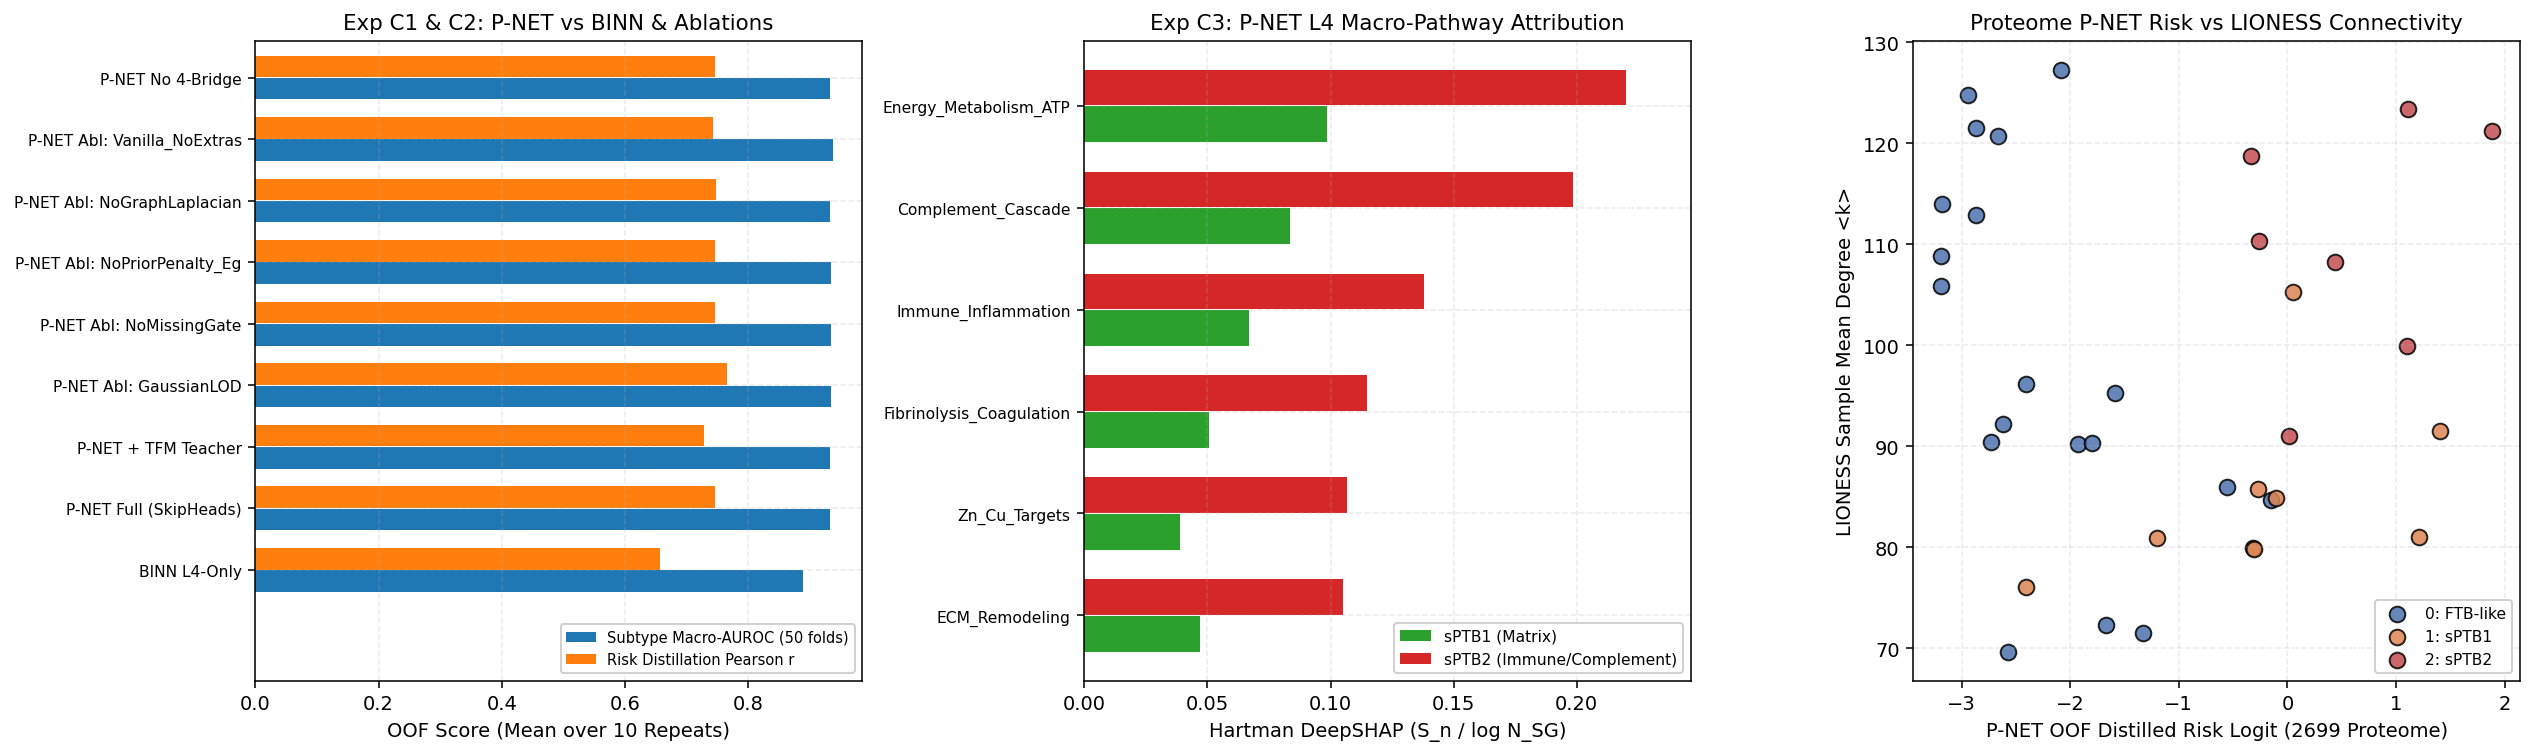

Готово: графики, таблицы и `artifacts.zip` для Трека C сохранены.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18.2, 5.5))

ax = axes[0]
ablation_keys = [
    "C1a_BINN_Full_BaseTeacher",
    "C1b_PNET_SkipHeads_BaseTeacher",
    "C1c_PNET_SkipHeads_TFMTeacher",
    "C2_PNET_Abl_GaussianLOD",
    "C2_PNET_Abl_NoMissingGate",
    "C2_PNET_Abl_NoPriorPenalty_Eg",
    "C2_PNET_Abl_NoGraphLaplacian",
    "C2_PNET_Abl_Vanilla_NoExtras",
    "C2b_PNET_AntiTautology_No4Bridge",
]
ablation_keys = [k for k in ablation_keys if k in track_c_results]
ab_labels = [
    k.replace("C1a_BINN_Full_BaseTeacher", "BINN L4-Only")
     .replace("C1b_PNET_SkipHeads_BaseTeacher", "P-NET Full (SkipHeads)")
     .replace("C1c_PNET_SkipHeads_TFMTeacher", "P-NET + TFM Teacher")
     .replace("C2_PNET_Abl_", "P-NET Abl: ")
     .replace("C2b_PNET_AntiTautology_No4Bridge", "P-NET No 4-Bridge")
    for k in ablation_keys
]
y_pos = np.arange(len(ablation_keys))
aucs = [track_c_results[k]["raw_macro_auc"] for k in ablation_keys]
r_vals = [track_c_results[k]["raw_risk_r"] for k in ablation_keys]
ax.barh(y_pos - 0.18, aucs, height=0.35, color="#1f77b4", label="Subtype Macro-AUROC (50 folds)")
ax.barh(y_pos + 0.18, r_vals, height=0.35, color="#ff7f0e", label="Risk Distillation Pearson r")
ax.set_yticks(y_pos)
ax.set_yticklabels(ab_labels, fontsize=8)
ax.set_ylim(-1.8, len(ablation_keys) - 0.4)
ax.set_xlabel("OOF Score (Mean over 10 Repeats)")
ax.set_title("Exp C1 & C2: P-NET vs BINN & Ablations")
ax.legend(fontsize=7.5, loc="lower right", framealpha=0.92)

ax = axes[1]
df_p = df_l4_biology.sort_values("PNET_SHAP_sPTB2", ascending=True)
yp2 = np.arange(len(df_p))
ax.barh(yp2 - 0.18, df_p["PNET_SHAP_sPTB1"], height=0.35, color="#2ca02c", label="sPTB1 (Matrix)")
ax.barh(yp2 + 0.18, df_p["PNET_SHAP_sPTB2"], height=0.35, color="#d62728", label="sPTB2 (Immune/Complement)")
ax.set_yticks(yp2)
ax.set_yticklabels(df_p["Macro_Pathway_L4"], fontsize=8)
ax.set_xlim(0.0, float(df_p["PNET_SHAP_sPTB2"].max()) * 1.12)
ax.set_xlabel("Hartman DeepSHAP (S_n / log N_SG)")
ax.set_title("Exp C3: P-NET L4 Macro-Pathway Attribution")
ax.legend(fontsize=8, loc="lower right", framealpha=0.92)

ax = axes[2]
colors_cl = {0: "#4c72b0", 1: "#dd8452", 2: "#c44e52"}
names_cl = {0: "0: FTB-like", 1: "1: sPTB1", 2: "2: sPTB2"}
for cl_i in [0, 1, 2]:
    msk = Y_SUBTYPE == cl_i
    ax.scatter(
        track_c_results["C1b_PNET_SkipHeads_BaseTeacher"]["oof_risk_logits"][msk],
        lioness_k[msk],
        s=65,
        color=colors_cl[cl_i],
        edgecolor="black",
        alpha=0.85,
        label=names_cl[cl_i],
    )
ax.set_xlabel("P-NET OOF Distilled Risk Logit (2699 Proteome)")
ax.set_ylabel("LIONESS Sample Mean Degree <k>")
ax.set_title("Proteome P-NET Risk vs LIONESS Connectivity")
ax.legend(fontsize=8, loc="lower right", framealpha=0.92)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "TrackC_BINN_DeepSHAP_Summary.png", dpi=300)
plt.show()

df_c1_c2.to_csv(TRACK_C_DIR / "exp_c1_c2_binn_ablations.csv", index=False)
df_l4_biology.to_csv(TRACK_C_DIR / "exp_c3_l4_pathway_deepshap.csv", index=False)
df_bio_markers.to_csv(TRACK_C_DIR / "exp_c3_key_biomarkers_deepshap.csv", index=False)
top20_df.to_csv(TRACK_C_DIR / "exp_c3_top20_nobridge_proteins.csv", index=False)
pd.DataFrame(lioness_rows).to_csv(TRACK_C_DIR / "exp_c3_lioness_uprofile.csv", index=False)

oof_cq_df = pd.DataFrame({
    "Sample_ID": SAMPLE_IDS_CQ,
    "True_Subtype_Cluster": Y_SUBTYPE,
    "Pure_JSD_Cluster": Y_PURE_JSD,
    "Teacher_Logit_Soft": Y_SOFT_LOGIT,
    "PNET_OOF_Risk_Logit": track_c_results["C1b_PNET_SkipHeads_BaseTeacher"]["oof_risk_logits"],
    "BINN_OOF_Risk_Logit": track_c_results["C1a_BINN_Full_BaseTeacher"]["oof_risk_logits"],
    "PNET_NoBridge_Risk_Logit": track_c_results["C2b_PNET_AntiTautology_No4Bridge"]["oof_risk_logits"],
    "PNET_OOF_Prob_C0": track_c_results["C1b_PNET_SkipHeads_BaseTeacher"]["oof_cls_probs"][:, 0],
    "PNET_OOF_Prob_C1": track_c_results["C1b_PNET_SkipHeads_BaseTeacher"]["oof_cls_probs"][:, 1],
    "PNET_OOF_Prob_C2": track_c_results["C1b_PNET_SkipHeads_BaseTeacher"]["oof_cls_probs"][:, 2],
    "PNET_OOF_Pred_Subtype": pred_subtype_oof,
}).set_index("Sample_ID")
oof_cq_df.to_parquet(TRACK_C_DIR / "cq_binn_oof_predictions.parquet")

l0_export_df = pd.DataFrame({
    "Gene": PROTEIN_NAMES,
    "E_g": E_RAW,
    "Subgraph_N_SG": SUBGRAPH_SIZES[0],
    "Full_Risk_SHAP_Abs": np.mean(np.abs(shap_pnet_full["l0_risk_hartman"]), axis=0),
    "NoBridge_Risk_SHAP_Abs": np.mean(np.abs(shap_pnet_nobridge["l0_risk_hartman"]), axis=0),
    "sPTB1_SHAP": np.mean(shap_pnet_full["l0_cls_hartman"][m_c1, 1], axis=0),
    "sPTB2_SHAP": np.mean(shap_pnet_full["l0_cls_hartman"][m_c2, 2], axis=0),
}).set_index("Gene")
l0_export_df.to_parquet(TRACK_C_DIR / "cq_l0_protein_deepshap.parquet")

shutil.make_archive("artifacts", "zip", "artifacts")
print("Готово: графики, таблицы и `artifacts.zip` для Трека C сохранены.")